## Part 2: Hierarchical Clustering for Community Detection

### 2.2. Implementation

In [1]:
import networkx as nx
import itertools

def modularity(G, partition):
    """Compute modularity for a partition (list of sets of nodes)."""
    return nx.community.modularity(G, partition)

def hierarchical_communities(G, method='betweenness', agg=True):
    """
    Compute hierarchical communities using either:
    - Agglomerative clustering (modularity-based merging)
    - Divisive clustering (edge-betweenness)

    Returns:
        dendrogram: list of partitions at each step
        best_partition: partition with highest modularity
    """

    if agg:
        return agglomerative_modularity_clustering(G)
    else:
        return divisive_betweenness_clustering(G)

In [2]:
def agglomerative_modularity_clustering(G):
    dendrogram = []
    # Start with each node in its own community
    communities = [{n} for n in G.nodes()]
    dendrogram.append([c.copy() for c in communities])

    current_mod = modularity(G, communities)

    # Try merging until only 1 community remains
    while len(communities) > 1:
        best_gain = 0
        best_merge = None

        # Try all possible merges
        for i, j in itertools.combinations(range(len(communities)), 2):
            merged = communities[i] | communities[j]
            trial = [communities[k] for k in range(len(communities)) if k != i and k != j]
            trial.append(merged)

            mod = modularity(G, trial)
            gain = mod - current_mod

            if gain > best_gain:
                best_gain = gain
                best_merge = (i, j, merged, trial, mod)

        if best_merge is None:
            # No improvement possible
            break

        # Apply the best merge
        i, j, merged, new_coms, mod = best_merge
        communities = new_coms
        current_mod = mod

        dendrogram.append([c.copy() for c in communities])

    # Find best partition across dendrogram
    best_partition = max(dendrogram, key=lambda P: modularity(G, P))

    return dendrogram, best_partition

In [3]:
def divisive_betweenness_clustering(G):
    dendrogram = []
    # Start with all nodes in one community
    components = [set(G.nodes())]
    dendrogram.append([c.copy() for c in components])

    working_graph = G.copy()

    while working_graph.number_of_edges() > 0:
        # Compute edge betweenness
        bet = nx.edge_betweenness_centrality(working_graph)
        # Remove the highest-betweenness edge
        edge_to_remove = max(bet, key=bet.get)
        working_graph.remove_edge(*edge_to_remove)

        # Record new components
        components = [set(c) for c in nx.connected_components(working_graph)]
        dendrogram.append([c.copy() for c in components])

    # Find the best partition by modularity
    best_partition = max(dendrogram, key=lambda P: modularity(G, P))

    return dendrogram, best_partition

Graph loaded: Graph named "Zachary's Karate Club" with 34 nodes and 78 edges

=== AGGLOMERATIVE CLUSTERING ===
Best agglomerative partition: [{16, 4, 5, 6, 10}, {0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21}, {8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33}]
Agglomerative modularity: 0.4345214669889994

=== DIVISIVE CLUSTERING (BETWEENNESS) ===
Best divisive partition: [{0, 1, 3, 7, 11, 12, 13, 17, 19, 21}, {2, 24, 25, 27, 28, 31}, {16, 4, 5, 6, 10}, {32, 33, 8, 14, 15, 18, 20, 22, 23, 26, 29, 30}, {9}]
Divisive modularity: 0.3849721706864564


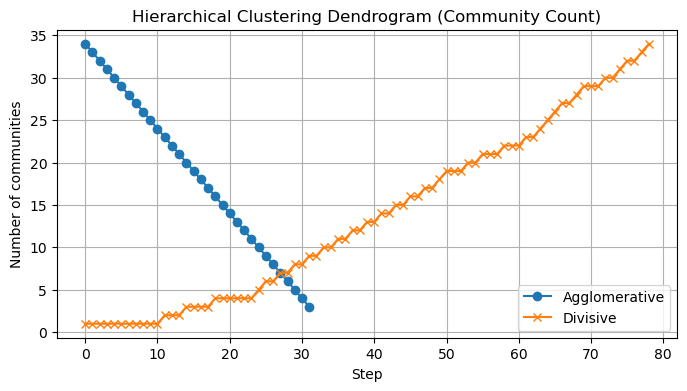


Agglomerative Best Partition
  Community 1: [4, 5, 6, 10, 16]
  Community 2: [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21]
  Community 3: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]

Divisive Best Partition
  Community 1: [0, 1, 3, 7, 11, 12, 13, 17, 19, 21]
  Community 2: [2, 24, 25, 27, 28, 31]
  Community 3: [4, 5, 6, 10, 16]
  Community 4: [8, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
  Community 5: [9]


In [4]:
import networkx as nx
import matplotlib.pyplot as plt

# ----------------------------------------------------
# Load test graph
# ----------------------------------------------------
G = nx.karate_club_graph()
print("Graph loaded:", G)

# ----------------------------------------------------
# Run Agglomerative Clustering
# ----------------------------------------------------
print("\n=== AGGLOMERATIVE CLUSTERING ===")
dendro_agg, best_agg = hierarchical_communities(G, agg=True)

mod_agg = nx.community.modularity(G, best_agg)
print("Best agglomerative partition:", best_agg)
print("Agglomerative modularity:", mod_agg)

# ----------------------------------------------------
# Run Divisive (Betweenness) Clustering
# ----------------------------------------------------
print("\n=== DIVISIVE CLUSTERING (BETWEENNESS) ===")
dendro_div, best_div = hierarchical_communities(G, agg=False)

mod_div = nx.community.modularity(G, best_div)
print("Best divisive partition:", best_div)
print("Divisive modularity:", mod_div)

# ----------------------------------------------------
# Plot evolution (number of communities per step)
# ----------------------------------------------------
plt.figure(figsize=(8,4))
plt.plot([len(p) for p in dendro_agg], label="Agglomerative", marker='o')
plt.plot([len(p) for p in dendro_div], label="Divisive", marker='x')
plt.xlabel("Step")
plt.ylabel("Number of communities")
plt.title("Hierarchical Clustering Dendrogram (Community Count)")
plt.legend()
plt.grid(True)
plt.show()

# ----------------------------------------------------
# Pretty-print partitions
# ----------------------------------------------------
def print_partition(partition, title):
    print("\n" + title)
    for i, com in enumerate(partition):
        print(f"  Community {i+1}: {sorted(list(com))}")

print_partition(best_agg, "Agglomerative Best Partition")
print_partition(best_div, "Divisive Best Partition")


In [5]:
import matplotlib.pyplot as plt
import networkx as nx
import random

def draw_community_graph(G, partition, title="Community Visualization"):
    """
    Draw the graph with nodes colored by community.
    partition = list of sets of nodes
    """
    # Assign each community a color
    colors = {}
    color_map = []

    # Generate distinct random colors
    community_colors = [
        (random.random(), random.random(), random.random())
        for _ in range(len(partition))
    ]

    for i, community in enumerate(partition):
        for node in community:
            colors[node] = community_colors[i]

    # Build color map for each node
    for node in G.nodes():
        color_map.append(colors[node])

    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=42)
    nx.draw(
        G,
        pos,
        node_color=color_map,
        with_labels=True,
        node_size=500,
        font_size=8,
        edge_color="gray"
    )
    plt.title(title)
    plt.show()


In [6]:
dendro_agg, best_agg = hierarchical_communities(G, agg=True)
dendro_div, best_div = hierarchical_communities(G, agg=False)


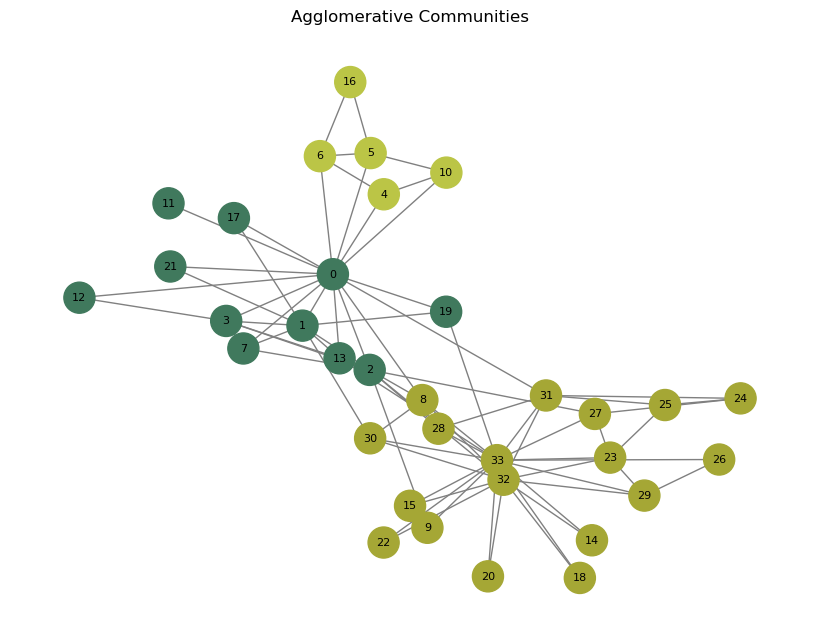

In [7]:
draw_community_graph(G, best_agg, title="Agglomerative Communities")


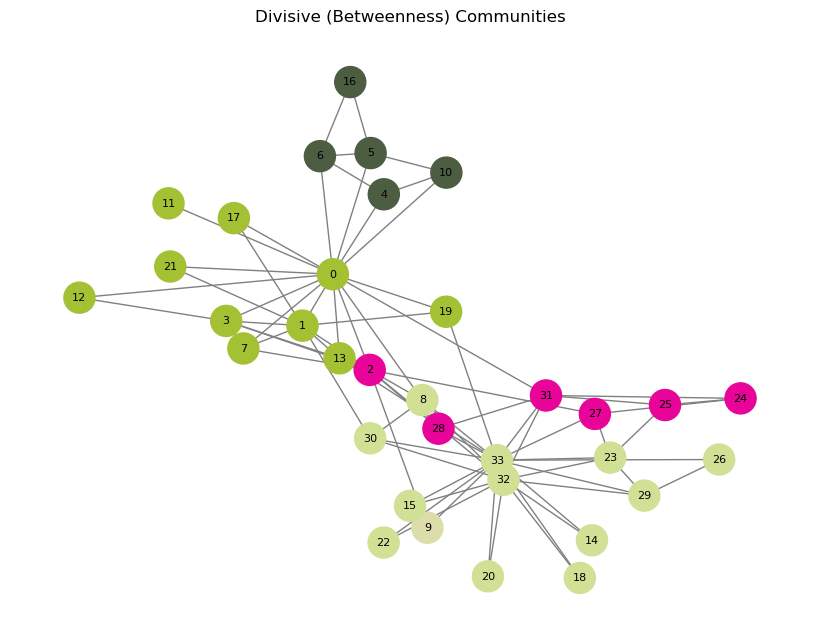

In [8]:
draw_community_graph(G, best_div, title="Divisive (Betweenness) Communities")


## Part 3: Modularity Optimization

In [10]:
import networkx as nx
import matplotlib.pyplot as plt
import community.community_louvain as louvain

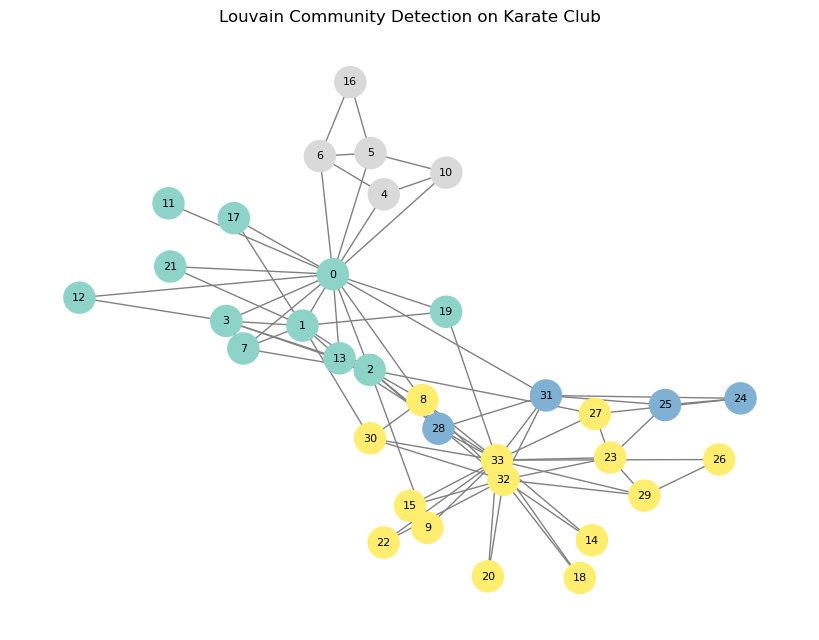

In [11]:
partition = louvain.best_partition(G)
plt.figure(figsize=(8, 6))

# Layout for nodes
pos = nx.spring_layout(G, seed=42)

# Color map (community ID → color)
communities = set(partition.values())
colors = [partition[n] for n in G.nodes()]

# Draw
nx.draw(
    G,
    pos,
    node_color=colors,
    with_labels=True,
    cmap=plt.cm.Set3,
    node_size=500,
    font_size=8,
    edge_color="gray"
)

plt.title("Louvain Community Detection on Karate Club")
plt.show()

## Part 4: Overlapping Communities

### 4.2. Clique Percolation Method (CPM)

In [12]:
def detect_overlapping_communities(G, k=3):
    # 1. Find all k-cliques
    cliques = []
    # enumerate_all_cliques generates cliques in increasing size
    for clique in nx.enumerate_all_cliques(G):
        if len(clique) == k:
            cliques.append(set(clique))
        elif len(clique) > k:
            # no need to check larger cliques
            break

    num_cliques = len(cliques)
    if num_cliques == 0:
        return [], [], []

    # 2. Build clique–clique overlap matrix
    overlap_matrix = [[0] * num_cliques for _ in range(num_cliques)]
    clique_graph = nx.Graph()
    clique_graph.add_nodes_from(range(num_cliques))

    for i in range(num_cliques):
        for j in range(i + 1, num_cliques):
            # Size of intersection
            inter_size = len(cliques[i].intersection(cliques[j]))
            if inter_size >= k - 1:
                overlap_matrix[i][j] = 1
                overlap_matrix[j][i] = 1
                clique_graph.add_edge(i, j)

    # 3. Connected components of cliques = communities
    communities = []
    for component in nx.connected_components(clique_graph):
        community_nodes = set()
        for clique_idx in component:
            community_nodes |= cliques[clique_idx]
        communities.append(community_nodes)

    return communities, cliques, overlap_matrix
    


In [13]:
G = nx.karate_club_graph()
communities, cliques, overlap = detect_overlapping_communities(G, k=3)

print("Number of 3-cliques:", len(cliques))
print("Number of communities:", len(communities))
for i, com in enumerate(communities):
    print(f"Community {i+1}:", sorted(com))


Number of 3-cliques: 45
Number of communities: 3
Community 1: [0, 1, 2, 3, 7, 8, 12, 13, 14, 15, 17, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 32, 33]
Community 2: [0, 4, 5, 6, 10, 16]
Community 3: [24, 25, 31]


## Part 5: Characterizing Communities

In [15]:
import networkx as nx

def community_metrics(G, partition):
    """
    Compute conductance, internal density, and average internal/external degree
    using NetworkX tools where possible.
    """
    metrics = {}

    for i, comm in enumerate(partition):
        S = set(comm)
        subG = G.subgraph(S)

        try:
            cond = nx.algorithms.cuts.conductance(G, S)
        except ZeroDivisionError:
            cond = 0.0
            
        density = nx.density(subG)

        inside_deg = []
        outside_deg = []

        for u in S:
            deg_in = sum(1 for v in G.neighbors(u) if v in S)
            inside_deg.append(deg_in)
            outside_deg.append(G.degree(u) - deg_in)

        metrics[i] = {
            "size": len(S),
            "internal_density": density,
            "conductance": cond,
            "avg_inside_degree": sum(inside_deg) / len(S),
            "avg_outside_degree": sum(outside_deg) / len(S)
        }

    return metrics


In [16]:
def node_roles(G, partition):
    """
    Classify nodes as hubs, bridges, or internal using NetworkX where possible.
    """
    # Map node -> community
    node2comm = {n: i for i, comm in enumerate(partition) for n in comm}

    roles = {}
    degrees = dict(G.degree())

    avg_deg = sum(degrees.values()) / len(G)

    for u in G.nodes():
        comm = node2comm[u]
        S = partition[comm]

        deg_in = sum(1 for v in G.neighbors(u) if v in S)
        deg_out = degrees[u] - deg_in

        # Role classification
        if deg_out > deg_in:
            role = "bridge"
        elif degrees[u] > avg_deg:
            role = "hub"
        else:
            role = "internal"

        roles[u] = {
            "community": comm,
            "inside_degree": deg_in,
            "outside_degree": deg_out,
            "total_degree": degrees[u],
            "role": role
        }

    return roles


In [17]:
import matplotlib.pyplot as plt

def visualize_roles(G, roles, title="Node Roles"):
    color_map = []

    for node in G.nodes():
        role = roles[node]["role"]
        if role == "hub":
            color_map.append("green")
        elif role == "bridge":
            color_map.append("red")
        else:
            color_map.append("blue")

    pos = nx.spring_layout(G, seed=42)

    plt.figure(figsize=(8, 6))
    nx.draw(
        G, pos,
        node_color=color_map,
        with_labels=True,
        node_size=600,
        edge_color="gray",
        font_size=9
    )
    plt.title(title)
    plt.show()



=== COMMUNITY METRICS ===
Community 0: {'size': 6, 'internal_density': 0.4666666666666667, 'conductance': 0.4166666666666667, 'avg_inside_degree': 2.3333333333333335, 'avg_outside_degree': 1.6666666666666667}
Community 1: {'size': 6, 'internal_density': 0.6666666666666666, 'conductance': 0.4444444444444444, 'avg_inside_degree': 3.3333333333333335, 'avg_outside_degree': 2.6666666666666665}
Community 2: {'size': 10, 'internal_density': 0.3111111111111111, 'conductance': 0.3, 'avg_inside_degree': 2.8, 'avg_outside_degree': 1.2}
Community 3: {'size': 12, 'internal_density': 0.3181818181818182, 'conductance': 0.25, 'avg_inside_degree': 3.5, 'avg_outside_degree': 1.1666666666666667}

=== NODE ROLES ===
0 {'community': 2, 'inside_degree': 8, 'outside_degree': 8, 'total_degree': 16, 'role': 'hub'}
1 {'community': 1, 'inside_degree': 4, 'outside_degree': 5, 'total_degree': 9, 'role': 'bridge'}
2 {'community': 1, 'inside_degree': 4, 'outside_degree': 6, 'total_degree': 10, 'role': 'bridge'}
3 {

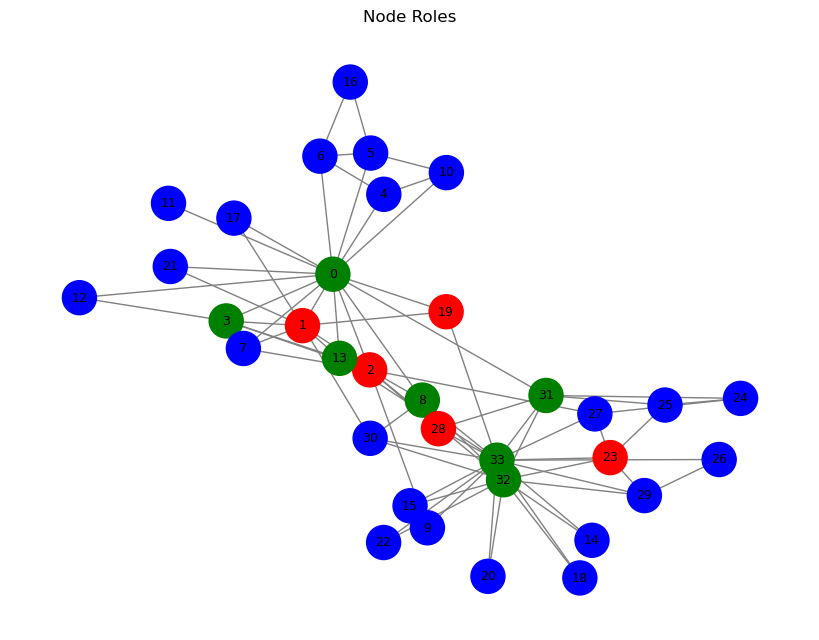

In [18]:
import community.community_louvain as louvain

# Load graph
G = nx.karate_club_graph()

# Louvain communities
partition_dict = louvain.best_partition(G)

# Convert dict → list-of-sets
partition = []
for c in set(partition_dict.values()):
    partition.append({n for n in G if partition_dict[n] == c})

# Compute metrics (NX-heavy)
metrics = community_metrics(G, partition)

print("\n=== COMMUNITY METRICS ===")
for cid, m in metrics.items():
    print(f"Community {cid}: {m}")

# Node roles (NX-heavy)
roles = node_roles(G, partition)

print("\n=== NODE ROLES ===")
for n, r in roles.items():
    print(n, r)

# Visualization
visualize_roles(G, roles)
